# Visual Product Finder — Part 3: Feature Extraction with ResNet50

**Previous steps:** Part 1 validated the data (`clean_products.csv`), Part 2 built a preprocessing pipeline matched to ResNet50.

**This notebook:** we use the pretrained **ResNet50** for the first time. Every product image is converted into an **embedding**: a vector of 2048 numbers describing what the image looks like.

## What is an embedding?

A CNN trained on ImageNet learns to detect visual patterns: edges and colours in early layers, textures and shapes in the middle, object parts in the last layers. If we stop the network **before** its final classification layer, what remains is a numeric summary of the image. Images with similar visual content get similar vectors, which means **"find similar products" becomes "find nearest vectors"**.

We use the network only as a **feature extractor** (Transfer Learning). We do not train anything.

## Goals

1. Load ResNet50 with pretrained weights and remove the classification layer
2. Understand how a `224×224×3` image becomes a 2048-number vector
3. Extract an embedding from one image, then from a batch, and verify shapes and properties
4. Measure speed and GPU memory, and check whether mixed precision (fp16) is safe
5. Extract embeddings for a fixed **subset** of products
6. Compare the two preprocessing options from Part 2 (**center crop vs. pad**) on this subset, changing **only one thing**

> **Requirements:** turn **Internet** on in the notebook settings (the pretrained weights are downloaded once), and add the Part 1 output (`clean_products.csv`) as an Input.

## 1. Setup

In [1]:
import os
import glob
import json
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from torchvision.models import resnet50, ResNet50_Weights

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0), "| GPUs visible:", torch.cuda.device_count())

PyTorch: 2.11.0+cu128
Device: cuda
GPU: Tesla T4 | GPUs visible: 2


### Configuration

All experiment settings live here, so every result can be traced back to its settings.

| Setting | Meaning |
|---------|---------|
| `WEIGHTS` | Which pretrained ResNet50 weights to use |
| `USE_AMP` | Mixed precision (fp16) on GPU for speed. We verify below that it does not change embeddings meaningfully |
| `SUBSET_SIZE` | Number of products used for today's experiments (the full catalog comes later) |
| `RUN_PAD_COMPARISON` | Also extract with the *pad* preprocessing and compare it with *crop* |

The notebook uses **one** GPU even if two are visible. Using both would add complexity and is not needed at this scale.

In [2]:
DATASET_PATH = Path("/kaggle/input/datasets/paramaggarwal/fashion-product-images-dataset/fashion-dataset/fashion-dataset")
IMAGE_DIR = DATASET_PATH / "images"
OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")

WEIGHTS = ResNet50_Weights.IMAGENET1K_V2
EMBEDDING_DIM = 2048

BATCH_SIZE = 64
NUM_WORKERS = 4
USE_AMP = True

SUBSET_SIZE = 5000
RUN_PAD_COMPARISON = True
N_EVAL_QUERIES = 1000
N_VISUAL_QUERIES = 4

def find_file(name):
    patterns = [f"/kaggle/working/{name}", f"/kaggle/input/*/{name}",
                f"/kaggle/input/*/*/{name}", f"/kaggle/input/*/*/*/{name}", name]
    for pattern in patterns:
        hits = sorted(glob.glob(pattern))
        if hits:
            return Path(hits[0])
    raise FileNotFoundError(f"{name} not found. Add the output of the earlier notebook as an Input.")

CLEAN_CSV = find_file("clean_products.csv")
print("Using:", CLEAN_CSV)

Using: /kaggle/input/notebooks/tahazarei/vpf-01-fashion-dataset-eda/clean_products.csv


## 2. Products and Preprocessing

We reload the verified product table and rebuild the preprocessing from Part 2. The preprocessing values are read from the pretrained weights, so they cannot drift away from what the model expects.

We define **two** preprocessing modes:

* **`crop`** (baseline): resize the shorter side to 232, then center-crop 224×224. This is the standard setup for these weights.
* **`pad`**: add white borders to make the image square, then resize to 224×224. The whole product stays visible and nothing is distorted, but it appears smaller. This assumes product photos have a white background, which we saw in the samples.

Everything else (weights, normalization, batch size) stays identical between the two modes.

In [3]:
clean_df = pd.read_csv(CLEAN_CSV)
clean_df["image_path"] = clean_df["image"].apply(lambda f: IMAGE_DIR / f)
print("Products:", len(clean_df))

official = WEIGHTS.transforms()
resize_size = official.resize_size[0]
crop_size = official.crop_size[0]
mean, std = official.mean, official.std
interpolation = official.interpolation

def pad_to_square(img, fill=(255, 255, 255)):
    w, h = img.size
    s = max(w, h)
    canvas = Image.new("RGB", (s, s), fill)
    canvas.paste(img, ((s - w) // 2, (s - h) // 2))
    return canvas

def build_preprocess(mode):
    if mode == "crop":
        ops = [T.Resize(resize_size, interpolation=interpolation), T.CenterCrop(crop_size)]
    elif mode == "pad":
        ops = [T.Lambda(pad_to_square), T.Resize(crop_size, interpolation=interpolation)]
    else:
        raise ValueError("mode must be 'crop' or 'pad'")
    return T.Compose(ops + [T.ToTensor(), T.Normalize(mean=mean, std=std)])

print("Resize:", resize_size, "| Crop:", crop_size)

Products: 44441
Resize: 232 | Crop: 224


In [4]:
class ProductImageDataset(Dataset):
    # Returns (tensor, row_index, ok). Broken images do not stop a long run.
    def __init__(self, dataframe, transform):
        self.paths = dataframe["image_path"].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        try:
            with Image.open(self.paths[idx]) as im:
                return self.transform(im.convert("RGB")), idx, True
        except Exception as e:
            print(f"Failed to load index {idx}: {e}")
            return torch.zeros(3, crop_size, crop_size), idx, False

def make_loader(dataframe, mode, batch_size=BATCH_SIZE):
    return DataLoader(
        ProductImageDataset(dataframe, build_preprocess(mode)),
        batch_size=batch_size, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"),
    )

## 3. Loading ResNet50

We load the architecture with the pretrained weights. If this cell fails with a connection error, **Internet is off** in the notebook settings.

In [5]:
try:
    model = resnet50(weights=WEIGHTS)
except Exception as e:
    raise RuntimeError("Could not download the pretrained weights. In Kaggle: Settings -> turn Internet on, then re-run.") from e

print("Original final layer:", model.fc)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 177MB/s]


Original final layer: Linear(in_features=2048, out_features=1000, bias=True)


The original last layer `fc` is a `Linear(2048 → 1000)` that scores the 1000 ImageNet classes. We do **not** want class scores. We want the 2048-number vector that goes **into** that layer, so we replace `fc` with `nn.Identity()`, a layer that passes its input through unchanged.

We also call `model.eval()`. This is important: ResNet contains BatchNorm layers that behave differently in training and evaluation mode. In evaluation mode the output is **deterministic**, which is exactly what we need for a catalog.

In [6]:
model.fc = nn.Identity()
model = model.to(device).eval()

n_params = sum(p.numel() for p in model.parameters())
print(f"Parameters without the classifier: {n_params / 1e6:.1f} M")
print("Top-level blocks:", [name for name, _ in model.named_children()])

Parameters without the classifier: 23.5 M
Top-level blocks: ['conv1', 'bn1', 'relu', 'maxpool', 'layer1', 'layer2', 'layer3', 'layer4', 'avgpool', 'fc']


### Following one image through the network

We attach small hooks to print the output shape of each block. This shows how the network gradually trades **spatial size** for **feature depth**, until a single 2048-number vector remains.

In [7]:
sample_row = clean_df.sample(1, random_state=SEED).iloc[0]
sample_img = Image.open(sample_row["image_path"]).convert("RGB")
sample_tensor = build_preprocess("crop")(sample_img)
print("Product:", sample_row["productDisplayName"], "|", sample_row["articleType"])
print("Input tensor:", tuple(sample_tensor.shape))

shapes = {}
def make_hook(name):
    def hook(module, inputs, output):
        shapes[name] = tuple(output.shape)
    return hook

handles = [m.register_forward_hook(make_hook(n)) for n, m in model.named_children()]
with torch.inference_mode():
    out = model(sample_tensor.unsqueeze(0).to(device))
for h in handles:
    h.remove()

for name, shape in shapes.items():
    print(f"{name:10s} -> {shape}")

Product: Doodle Girl Ballet School Black Tops | Tops
Input tensor: (3, 224, 224)
conv1      -> (1, 64, 112, 112)
bn1        -> (1, 64, 112, 112)
relu       -> (1, 64, 112, 112)
maxpool    -> (1, 64, 56, 56)
layer1     -> (1, 256, 56, 56)
layer2     -> (1, 512, 28, 28)
layer3     -> (1, 1024, 14, 14)
layer4     -> (1, 2048, 7, 7)
avgpool    -> (1, 2048, 1, 1)
fc         -> (1, 2048)


**How to read this (shape = batch, channels, height, width):**

* `conv1`, `maxpool`: the image is quickly shrunk from 224×224 to 56×56
* `layer1` ... `layer4`: each stage **halves** the spatial size and **increases** the channels (256 → 512 → 1024 → 2048). Early stages see small local patterns, late stages see large, abstract ones.
* `layer4` ends with a 7×7 grid of 2048-dimensional features
* `avgpool` averages the 7×7 grid into **one** vector of 2048 numbers per image
* `fc` (now `Identity`) passes it on: **this is our embedding**

## 4. Our First Embedding

Success criterion for today: put one image into ResNet50 and get its embedding.

Embedding shape: (2048,)
dtype: torch.float32
Min / max / mean: 0.0 4.197 0.032
L2 norm: 8.055
Non-negative values only: True
First 8 values: [0.0, 0.007, 0.0, 0.0, 0.0, 0.0, 0.109, 0.0]


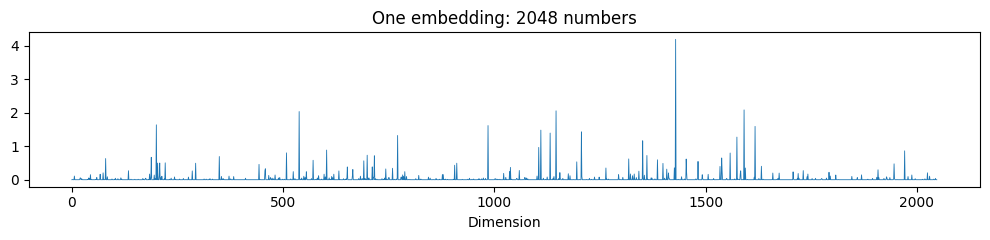

In [8]:
embedding = out.squeeze(0).cpu()

print("Embedding shape:", tuple(embedding.shape))
print("dtype:", embedding.dtype)
print("Min / max / mean:", round(embedding.min().item(), 3), round(embedding.max().item(), 3), round(embedding.mean().item(), 3))
print("L2 norm:", round(embedding.norm().item(), 3))
print("Non-negative values only:", bool((embedding >= 0).all()))
print("First 8 values:", [round(v, 3) for v in embedding[:8].tolist()])

plt.figure(figsize=(10, 2.5))
plt.plot(embedding.numpy(), linewidth=0.6)
plt.title("One embedding: 2048 numbers")
plt.xlabel("Dimension")
plt.tight_layout()
plt.show()

**Observations:**

* The values are all **non-negative**, because the last operation before pooling in ResNet is a ReLU. This is a useful sanity check of the pipeline.
* The vector has **no unit length** (its L2 norm is some arbitrary number). For similarity search we will **L2-normalize** every embedding, so that a dot product equals the **cosine similarity**. A bigger norm would otherwise favour some images over others for reasons unrelated to appearance.

### Is the output deterministic?
The same image must always give the same embedding. If it does not, the model is accidentally still in training mode.

In [9]:
with torch.inference_mode():
    out_again = model(sample_tensor.unsqueeze(0).to(device)).squeeze(0).cpu()

print("Max difference between two runs:", (embedding - out_again).abs().max().item())
print("Deterministic:", bool(torch.allclose(embedding, out_again, atol=1e-5)))

Max difference between two runs: 0.0
Deterministic: True


## 5. A Small Batch

We now process a random batch of products and check the output shape. We also L2-normalize the embeddings and compute the cosine similarity between all pairs in the batch.

In [10]:
batch_df = clean_df.sample(BATCH_SIZE, random_state=SEED).reset_index(drop=True)
images, idx, ok = next(iter(make_loader(batch_df, "crop")))

with torch.inference_mode():
    feats = model(images.to(device)).float()
feats_norm = F.normalize(feats, p=2, dim=1)

print("Images batch:", tuple(images.shape))
print("Embeddings:", tuple(feats.shape))
print("Norms after normalization (should be 1):", feats_norm.norm(dim=1)[:5].tolist())

sim = (feats_norm @ feats_norm.T).cpu()
off_diag = sim[~torch.eye(len(sim), dtype=torch.bool)]
print("Self-similarity (diagonal, should be 1):", round(sim.diag().mean().item(), 4))
print("Similarity between different products -> min/mean/max:",
      round(off_diag.min().item(), 3), round(off_diag.mean().item(), 3), round(off_diag.max().item(), 3))

Images batch: (64, 3, 224, 224)
Embeddings: (64, 2048)
Norms after normalization (should be 1): [1.0, 0.9999998807907104, 1.0, 0.9999999403953552, 0.9999999403953552]
Self-similarity (diagonal, should be 1): 1.0
Similarity between different products -> min/mean/max: 0.027 0.229 0.915


The diagonal is 1 (an image is identical to itself). Between different products the similarity is **high on average** (embeddings from a ReLU network are all non-negative, so they point in roughly similar directions). This is normal. What matters is the **ranking**: similar products should receive higher scores than dissimilar ones. We check this in section 8.

## 6. Speed and Memory

We have about 44k images to process eventually, so we measure how fast the model is on its own, using random input so that disk speed is not included. We compare:

* **fp32** (full precision) and **fp16** (mixed precision, much faster on modern GPUs)
* three batch sizes

and record peak GPU memory.

In [11]:
def benchmark(batch_size, amp, iters=10):
    x = torch.randn(batch_size, 3, crop_size, crop_size, device=device)
    use_amp = amp and device.type == "cuda"
    with torch.inference_mode(), torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
        for _ in range(3):
            model(x)                                  # warm-up
        if device.type == "cuda":
            torch.cuda.synchronize()
            torch.cuda.reset_peak_memory_stats()
        start = time.time()
        for _ in range(iters):
            model(x)
        if device.type == "cuda":
            torch.cuda.synchronize()
    elapsed = time.time() - start
    mem = torch.cuda.max_memory_allocated() / 1024**2 if device.type == "cuda" else float("nan")
    return batch_size * iters / elapsed, mem

rows = []
for amp in ([False, True] if device.type == "cuda" else [False]):
    for bs in [32, 64, 128]:
        speed, mem = benchmark(bs, amp)
        rows.append({"precision": "fp16" if amp else "fp32", "batch_size": bs,
                     "images_per_sec": round(speed, 1), "peak_gpu_mem_MB": round(mem)})
bench_df = pd.DataFrame(rows)
bench_df

,precision,batch_size,images_per_sec,peak_gpu_mem_MB
0,fp32,32,362.4,436
1,fp32,64,361.1,773
2,fp32,128,353.9,1447
3,fp16,32,779.3,289
4,fp16,64,799.2,479
5,fp16,128,806.9,859


**How to read it:** `images_per_sec` is the speed of the **model alone**. In the real pipeline, the speed is limited by whichever is slower: the model (GPU) or image loading (CPU). We measure the real, end-to-end speed in section 7.

### Is fp16 safe for embeddings?
Mixed precision is faster, but it changes numbers slightly. We verify the change is negligible by comparing fp16 and fp32 embeddings of the same batch.

In [12]:
if device.type == "cuda":
    with torch.inference_mode():
        f32 = F.normalize(model(images.to(device)).float(), dim=1)
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            f16 = F.normalize(model(images.to(device)).float(), dim=1)
    cos = (f32 * f16).sum(dim=1).cpu()
    print("Cosine similarity between fp32 and fp16 embeddings -> min/mean:",
          round(cos.min().item(), 5), round(cos.mean().item(), 5))
else:
    print("CPU run: fp16 comparison skipped.")

Cosine similarity between fp32 and fp16 embeddings -> min/mean: 0.99993 0.99998


If the minimum is very close to 1 (for example above 0.999), fp16 gives practically the same embeddings and `USE_AMP = True` is safe. If not, set `USE_AMP = False`.

## 7. The Extraction Function

One function converts a table of products into an embedding matrix. Design points:

* **Same order as the table.** `shuffle=False`, and every embedding is written to the row given by the dataset's index. Row *i* of the embeddings always belongs to row *i* of the table.
* **L2-normalized** output, ready for cosine similarity.
* **Failures are recorded,** not hidden: a boolean mask marks images that could not be loaded.
* `torch.inference_mode()` disables gradient tracking, which saves memory and time.

In [13]:
@torch.inference_mode()
def extract_embeddings(dataframe, mode, batch_size=BATCH_SIZE, use_amp=USE_AMP, desc=None):
    loader = make_loader(dataframe, mode, batch_size)
    feats = torch.zeros(len(dataframe), EMBEDDING_DIM)
    ok_mask = torch.zeros(len(dataframe), dtype=torch.bool)
    amp_on = use_amp and device.type == "cuda"

    for x, idx, ok in tqdm(loader, desc=desc or mode):
        x = x.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp_on):
            f = model(x)
        feats[idx] = F.normalize(f.float(), p=2, dim=1).cpu()
        ok_mask[idx] = ok

    feats[~ok_mask] = 0
    return feats.numpy(), ok_mask.numpy()

## 8. Embeddings for a Fixed Subset

For today's experiments we use a random subset of **`SUBSET_SIZE`** products. The subset is chosen once with a fixed seed and **kept identical for every experiment**. The column `catalog_row` stores each product's row in the full catalog, so we can always map back.

The first run also measures the **real end-to-end speed** (disk + preprocessing + model) and lets us estimate the full catalog run.

In [14]:
subset_df = clean_df.sample(SUBSET_SIZE, random_state=SEED).copy()
subset_df["catalog_row"] = subset_df.index
subset_df = subset_df.reset_index(drop=True)
print("Subset:", len(subset_df), "products")

results = {}
timings = {}

start = time.time()
emb_crop, ok_crop = extract_embeddings(subset_df, "crop")
timings["crop"] = time.time() - start

results["crop"] = emb_crop
speed = len(subset_df) / timings["crop"]

print("Embeddings:", emb_crop.shape, emb_crop.dtype)
print("Failed images:", int((~ok_crop).sum()))
print(f"End-to-end speed: {speed:.1f} images/second")
print(f"Estimated time for the full catalog ({len(clean_df):,} images): {len(clean_df) / speed / 60:.1f} minutes")

Subset: 5000 products


crop:   0%|          | 0/79 [00:00<?, ?it/s]

Embeddings: (5000, 2048) float32
Failed images: 0
End-to-end speed: 40.4 images/second
Estimated time for the full catalog (44,441 images): 18.3 minutes


If the end-to-end speed is much lower than the model-only speed from section 6, the bottleneck is **reading and resizing large images on the CPU**, not the GPU. In that case more workers or smaller pre-resized copies of the images would help.

In [15]:
if RUN_PAD_COMPARISON:
    start = time.time()
    emb_pad, ok_pad = extract_embeddings(subset_df, "pad")
    timings["pad"] = time.time() - start
    results["pad"] = emb_pad
    print("Pad embeddings:", emb_pad.shape, "| failed:", int((~ok_pad).sum()), "| time:", round(timings["pad"], 1), "s")

pad:   0%|          | 0/79 [00:00<?, ?it/s]

Pad embeddings: (5000, 2048) | failed: 0 | time: 111.9 s


## 9. Do Similar Products Get Similar Embeddings?

An embedding is only useful if **nearby vectors mean similar-looking products**. We test this in two ways: a **number** and a **visual check**. Both use exactly the same queries for every mode.

### 9.1 A rough number: precision@5

For many query products we find the 5 nearest products (by cosine similarity, excluding the query itself) and check how many have the **same category** as the query.

> **Important limitation:** this is only a **rough proxy**. Same category does not equal visually similar: two different shirts of the same type can look nothing alike, and two different categories (for example *Casual Shoes* and *Sports Shoes*) can look very similar yet count as a miss. Use it to **compare modes**, not as a final quality score.

In [16]:
rng = np.random.RandomState(SEED)
eval_queries = rng.choice(len(subset_df), size=min(N_EVAL_QUERIES, len(subset_df)), replace=False)

@torch.inference_mode()
def top_k_neighbors(emb, query_ids, k=5):
    E = torch.tensor(emb, device=device)
    q = torch.tensor(query_ids, device=device)
    sims = E[q] @ E.T
    sims[torch.arange(len(q)), q] = -1          # a product is not its own neighbour
    scores, top = sims.topk(k, dim=1)
    return scores.cpu().numpy(), top.cpu().numpy()

def precision_at_k(emb, label_col, k=5):
    _, top = top_k_neighbors(emb, eval_queries, k)
    labels = subset_df[label_col].fillna("NA").to_numpy()
    return float((labels[top] == labels[eval_queries][:, None]).mean())

rows = []
for mode, emb in results.items():
    rows.append({
        "mode": mode,
        "masterCategory": round(precision_at_k(emb, "masterCategory"), 4),
        "subCategory": round(precision_at_k(emb, "subCategory"), 4),
        "articleType": round(precision_at_k(emb, "articleType"), 4),
    })
precision_df = pd.DataFrame(rows).set_index("mode")
precision_df

,masterCategory,subCategory,articleType
mode,,,
crop,0.9910,0.9110,0.7572
pad,0.9888,0.9042,0.7432


Higher is better. `masterCategory` is the easiest level (7 groups) and `articleType` the strictest (143 groups). Because we compare modes on **identical queries and an identical subset**, a difference between rows reflects the preprocessing, although small differences may also be noise from the random subset.

### 9.2 The visual check

Numbers can hide problems that are obvious to the eye, so we look at real results. We pick one query from each of the most common article types. For each query, every mode shows its 5 nearest products with similarity scores. A **green** title means the neighbour has the same article type, **red** means it does not (which is not necessarily wrong: it may still look similar).

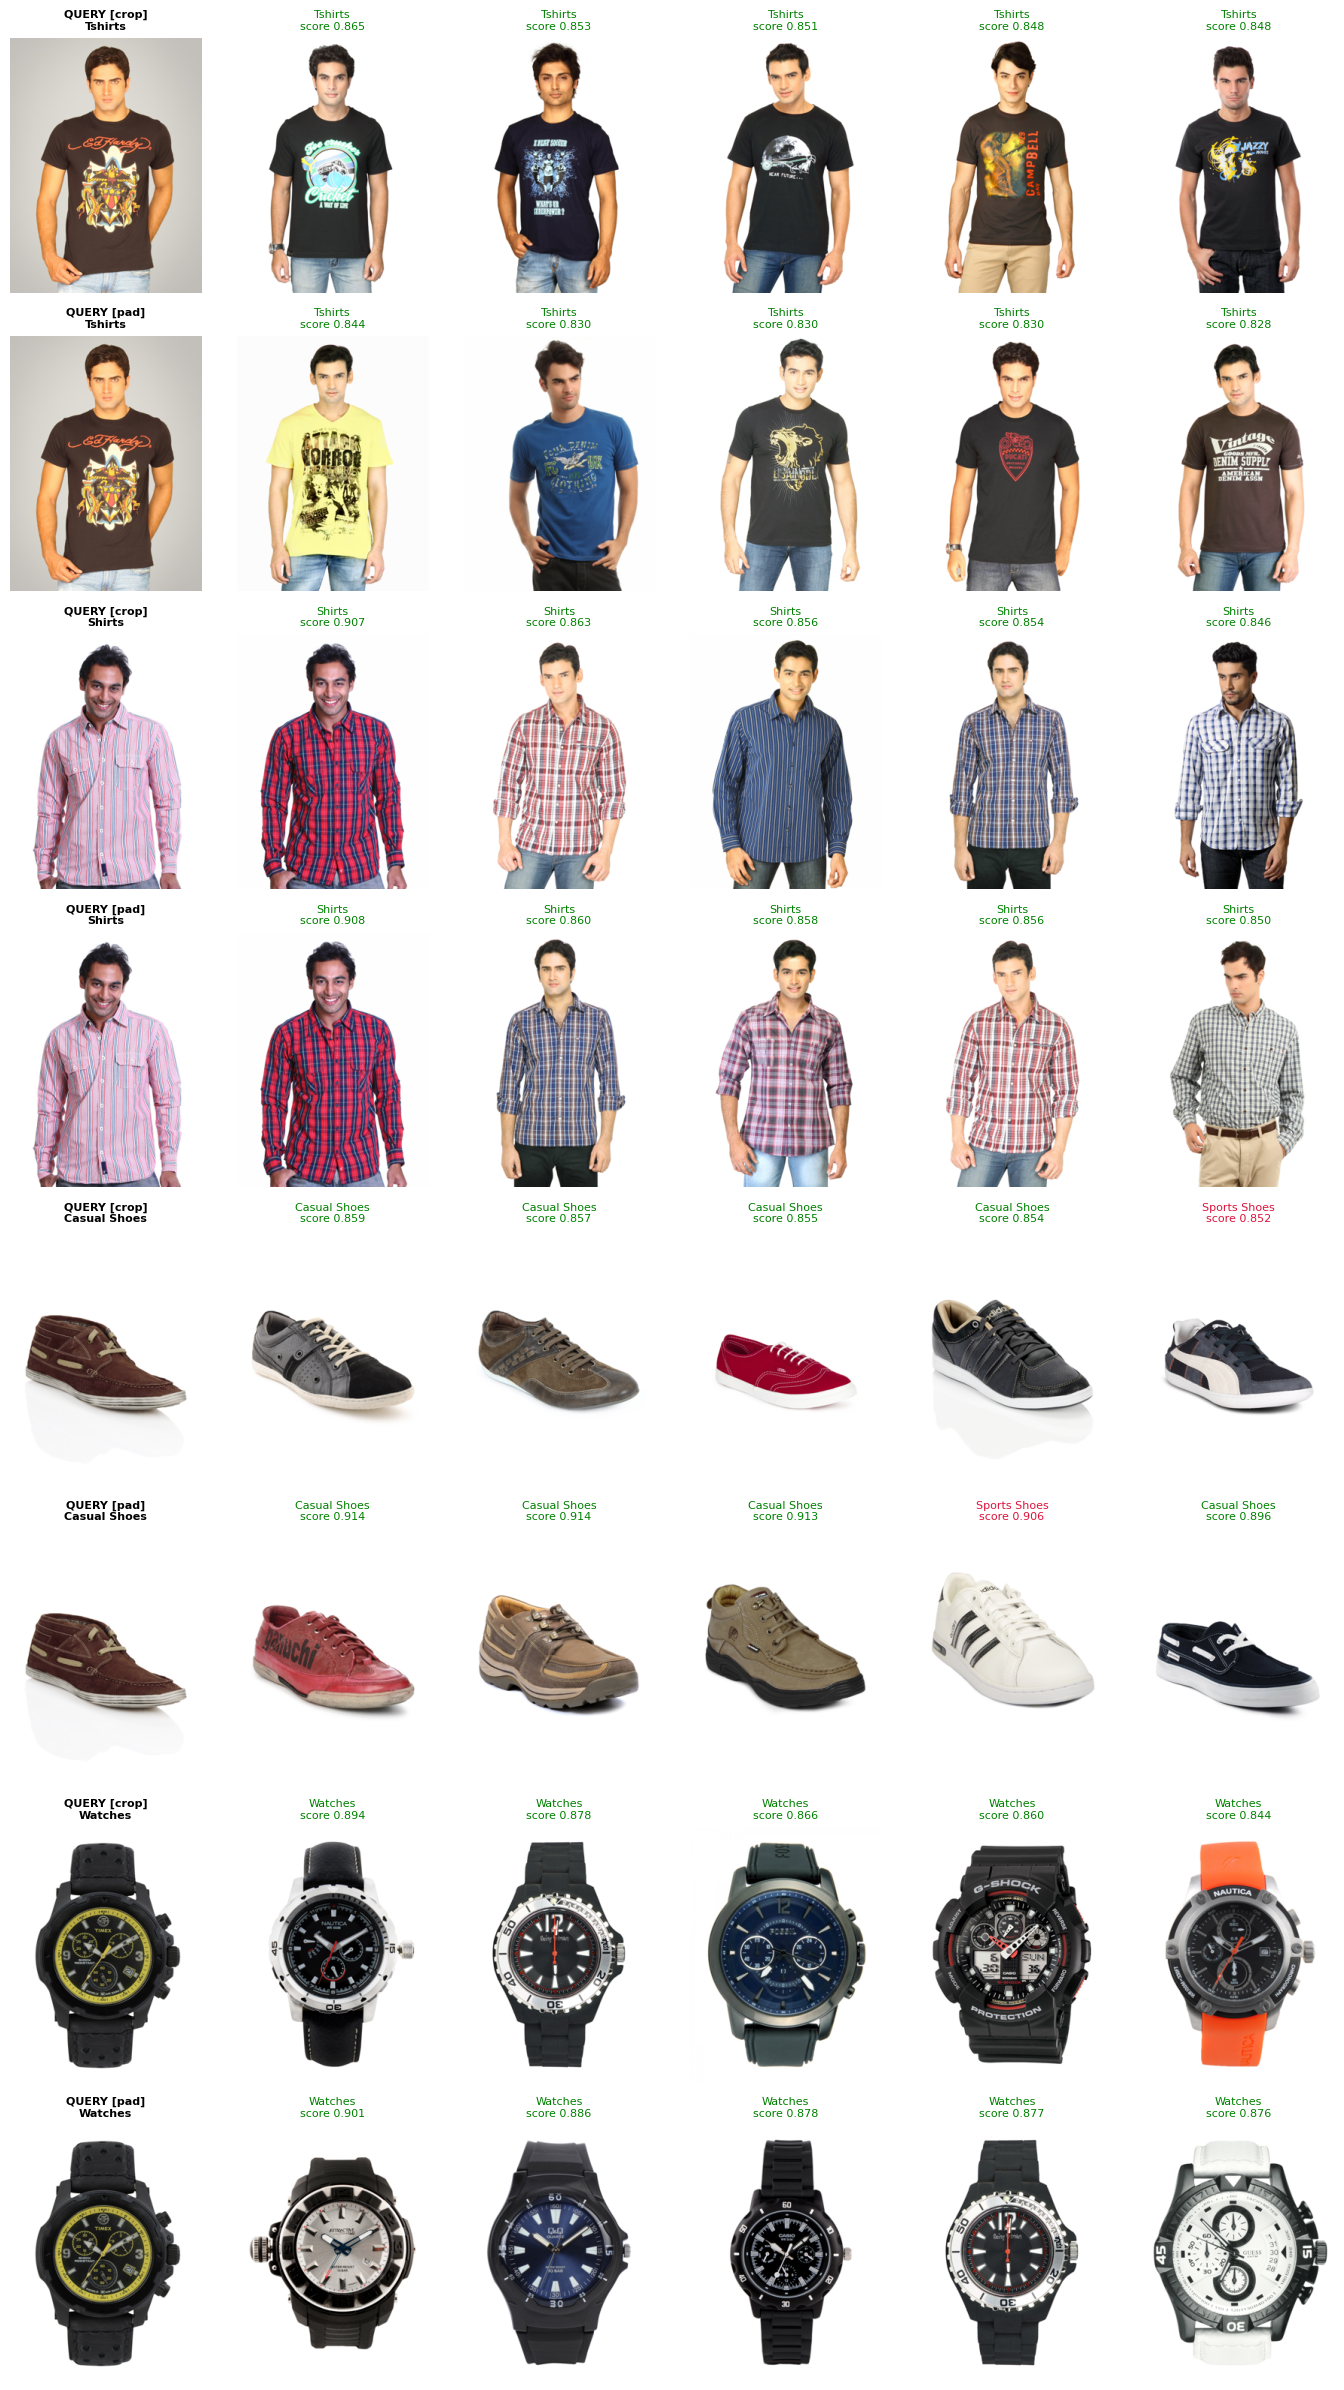

In [17]:
def load_thumb(path, max_size=(260, 340)):
    im = Image.open(path).convert("RGB")
    im.thumbnail(max_size)
    return im

top_types = subset_df["articleType"].value_counts().head(N_VISUAL_QUERIES).index
visual_queries = [int(subset_df.index[subset_df["articleType"] == t][0]) for t in top_types]

def show_results(query_ids, emb_by_mode, k=5):
    modes = list(emb_by_mode)
    n_rows = len(query_ids) * len(modes)
    fig, axes = plt.subplots(n_rows, k + 1, figsize=(2.3 * (k + 1), 3.0 * n_rows))
    axes = np.atleast_2d(axes)
    r = 0
    for q in query_ids:
        q_type = subset_df.loc[q, "articleType"]
        for mode in modes:
            scores, top = top_k_neighbors(emb_by_mode[mode], [q], k)
            axes[r, 0].imshow(load_thumb(subset_df.loc[q, "image_path"]))
            axes[r, 0].set_title(f"QUERY [{mode}]\n{q_type}", fontsize=8, fontweight="bold")
            for j in range(k):
                n = int(top[0, j])
                n_type = subset_df.loc[n, "articleType"]
                axes[r, j + 1].imshow(load_thumb(subset_df.loc[n, "image_path"]))
                axes[r, j + 1].set_title(f"{n_type}\nscore {scores[0, j]:.3f}", fontsize=8,
                                         color="green" if n_type == q_type else "crimson")
            for c in range(k + 1):
                axes[r, c].axis("off")
            r += 1
    plt.tight_layout()
    plt.show()

show_results(visual_queries, results)

### How to judge what you see

For each query, ask honestly:

* Are the neighbours the **same kind of product**?
* Do **colour, pattern and shape** match, or only the category?
* Does one mode keep more of the product visible (for example the lower part of long items), and does that change the results?
* Which mistakes are **reasonable** (a similar-looking product from a neighbouring category) and which are **clearly wrong**?

Write down your observations. They go into the evaluation section of the project documentation, and they tell us whether fine-tuning will be needed later.

## 10. Saving the Results

We save the subset embeddings (one file per mode), the subset's product table in the **same row order**, and a record of the settings and measurements. The product table and the embedding rows must always stay aligned.

In [18]:
subset_df.drop(columns=["image_path"]).to_csv(OUTPUT_DIR / "subset_products.csv", index=False)

for mode, emb in results.items():
    np.save(OUTPUT_DIR / f"subset_embeddings_{mode}.npy", emb.astype("float32"))

config = {
    "weights": str(WEIGHTS),
    "embedding_dim": EMBEDDING_DIM,
    "normalized": "L2",
    "mixed_precision": bool(USE_AMP and device.type == "cuda"),
    "batch_size": BATCH_SIZE,
    "subset_size": SUBSET_SIZE,
    "seed": SEED,
    "preprocess": {"resize_size": resize_size, "crop_size": crop_size,
                   "mean": list(mean), "std": list(std), "interpolation": interpolation.value},
    "extraction_seconds": {k: round(v, 1) for k, v in timings.items()},
    "precision_at_5": precision_df.to_dict(orient="index"),
}
with open(OUTPUT_DIR / "extraction_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("Saved files:", sorted(p.name for p in OUTPUT_DIR.glob("subset_*")) + ["extraction_config.json"])
print("Row alignment check:", len(subset_df) == results["crop"].shape[0])

Saved files: ['subset_embeddings_crop.npy', 'subset_embeddings_pad.npy', 'subset_products.csv', 'extraction_config.json']
Row alignment check: True


## 11. Summary

In this notebook we used a pretrained **ResNet50** (classifier removed) to turn product images into 2048-dimensional embeddings, measured the cost of doing so, and compared two preprocessing options on a fixed subset of 5,000 products.

### Key measurements

| Item | Result |
|------|--------|
| Model | ResNet50 `IMAGENET1K_V2`, classifier replaced by `Identity` |
| Embedding | 2048 numbers per image, L2-normalized |
| Parameters (without classifier) | 23.5 M |
| Model-only speed, fp32 | ≈ 375 images/second |
| Model-only speed, fp16 | ≈ 830 images/second (about 2.2× faster) |
| Peak GPU memory, batch 64 | 773 MB (fp32), 479 MB (fp16) |
| fp16 vs fp32 embeddings (cosine similarity) | min 0.99993, mean 0.99998 |
| End-to-end speed (crop) | 48.1 images/second (104 s for 5,000 images) |
| End-to-end speed (pad) | ≈ 45 images/second (110 s for 5,000 images) |
| Estimated time for the full catalog | ≈ 15 minutes (44,441 images) |
| Images that failed to load | 0 |

**The model is not the bottleneck.** The model alone runs at about 830 images/second, but the full pipeline reaches only about 48. The difference comes from reading and decoding large JPEGs (mostly 1080×1440 and 1800×2400) on 4 CPU cores. Larger batches did not help (speed stayed flat from batch size 32 to 128).

**fp16 is safe.** Mixed-precision embeddings are practically identical to fp32 ones, so we keep `USE_AMP = True`.

### Crop vs. pad (same 5,000 products, same 1,000 queries)

Precision@5 is a **rough proxy**: the share of the 5 nearest neighbours that have the same category as the query.

| Mode | masterCategory | subCategory | articleType |
|------|----------------|-------------|-------------|
| crop | 0.9910 | 0.9110 | 0.7572 |
| pad | 0.9888 | 0.9042 | 0.7432 |

Broken down by article type (types with at least 20 queries), crop was ahead in 9 of 15 types, pad in 3, and 3 were tied. Most differences were below 0.04, and the larger ones (for example Sandals −0.127, Tops +0.054) come from small groups of 22 to 37 queries. There was **no consistent pattern**: pad was not better for shoes in general (better for Sports Shoes and Heels, worse for Sandals, Flip Flops and Casual Shoes).

**Decision:** we keep **center crop**. It is the standard setup for these weights, it is slightly ahead overall, and we found no evidence that padding helps.

### Visual check

For queries from four common article types (T-shirts, shirts, casual shoes, watches), the nearest neighbours were products of the right type and often with similar colour, pattern and style. Several results marked as "wrong" by the category proxy were visually reasonable (for example a white sports shoe returned for a casual shoe).

### Limitations and observations

These are preliminary observations from a small number of examples, not established findings.

* **Category match is an imperfect measure.** Visually similar products from neighbouring categories (for example Casual Shoes and Sports Shoes) count as misses, so the absolute `articleType` score understates real quality.
* **Possible influence of pose and model.** In T-shirt and shirt queries, most results showed a similar standing pose, which suggests that part of the similarity may come from the person rather than the garment. This should be checked on more examples.
* **Weaker categories:** `Tops` (≈ 0.43 to 0.48), `Heels` (≈ 0.60) and the shoe categories (≈ 0.68) scored lowest. A likely reason is overlapping category boundaries (for example Tops vs. T-shirts vs. Shirts), but this was not verified.
* The embedding model was never trained for fashion similarity, so fine-tuning remains an option if the final evaluation shows clear failures.

### What we learned

* ResNet50 turns a `3×224×224` image into a 2048-number vector by shrinking the spatial size while increasing the feature depth.
* Evaluation mode (`model.eval()`) is required for reproducible embeddings.
* L2 normalization makes the dot product equal to cosine similarity.
* Comparing two options only makes sense with identical queries and one change at a time.

### Final settings for the catalog

| Setting | Value |
|---------|-------|
| Weights | `IMAGENET1K_V2` |
| Preprocessing | resize 232, center crop 224, ImageNet normalization |
| Precision | fp16 (mixed precision) |
| Batch size | 64 |
| Embedding normalization | L2 |

## Next: Part 4 — The Search Engine

We extract embeddings for **all 44,441 products** with these settings, save them in the same order as the product table (`catalog_embeddings.npy`, `products.csv`, `model_config.json`), and build the cosine-similarity search that the API will use.